In [1]:
import pandas as pd

In [2]:
vendas = pd.read_csv("../data/vendas_restaurante.csv")


In [3]:
vendas.loc[
    (vendas["produto"] == "Bife acebolado") & (vendas["preco_unitario"].isna()),
    "preco_unitario"
] = 32

In [4]:
vendas.loc[
    (vendas["produto"] == "Feijoada") & (vendas["preco_unitario"].isna()),
    "preco_unitario"
] = 38

In [5]:
vendas[
    vendas["produto"].isin(
        ["Pudim", "Prato feito", "Hambúrguer artesanal", "Café expresso"]
    )
].groupby("produto")["categoria"].unique()

produto
Café expresso                     [Bebidas, nan]
Hambúrguer artesanal              [Lanches, nan]
Prato feito             [Pratos principais, nan]
Pudim                          [Sobremesas, nan]
Name: categoria, dtype: object

In [6]:
vendas.loc[
    (vendas["produto"] == "Pudim") & (vendas["categoria"].isna()),
    "categoria"
] = "Sobremesas"

In [7]:
vendas.loc[
    (vendas["produto"] == "Café expresso") & (vendas["categoria"].isna()),
    "categoria"
] = "Bebidas"

In [8]:
vendas.loc[
    (vendas["produto"] == "Hambúrguer artesanal") & (vendas["categoria"].isna()),
    "categoria"
] = "Lanches"

In [9]:
vendas.loc[
    (vendas["produto"] == "Prato feito") & (vendas["categoria"].isna()),
    "categoria"
] = "Pratos principais"

In [10]:
vendas.isna().sum()


data               0
produto            0
categoria          0
quantidade         0
preco_unitario     0
forma_pagamento    6
dtype: int64

In [11]:
vendas.loc[vendas["categoria"].isna(), ["produto", "categoria"]]

,produto,categoria


In [12]:
vendas[vendas["forma_pagamento"].isna()]

,data,produto,categoria,quantidade,preco_unitario,forma_pagamento
202,2026-01-10,Batata frita,Porções,2,22.0,NaN
1328,2026-02-28,Bife acebolado,Pratos principais,2,32.0,NaN
1411,2026-03-04,Pudim,Sobremesas,1,10.0,NaN
1861,2026-03-23,Refrigerante lata,Bebidas,2,7.0,NaN
4025,2026-06-20,Refrigerante lata,Bebidas,2,7.0,NaN
4165,2026-06-25,Lasanha,Pratos principais,2,35.0,NaN


In [13]:
vendas["forma_pagamento"] = vendas["forma_pagamento"].fillna("Não informado")

In [14]:
vendas.isna().sum()

data               0
produto            0
categoria          0
quantidade         0
preco_unitario     0
forma_pagamento    0
dtype: int64

In [15]:
vendas["forma_pagamento"].value_counts()

forma_pagamento
Pix                  1821
Cartão de crédito    1250
Cartão de débito      865
Dinheiro              364
Não informado           6
pix                     6
Name: count, dtype: int64

In [16]:
vendas["forma_pagamento"] = vendas["forma_pagamento"].replace("pix", "Pix")

In [17]:
vendas["produto"].unique()

<StringArray>
[           'Prato feito',           'Salada verde',   'Hambúrguer artesanal',
                'Lasanha',         'Mandioca frita',                  'Pudim',
           'Água mineral',      'Refrigerante lata',        'Frango grelhado',
      'Risoto de legumes',           'Batata frita',                'Brownie',
               'Feijoada',         'Bife acebolado',        'Suco de laranja',
                'Sorvete',      'Sanduíche natural',      ' Frango grelhado ',
          'Café expresso', ' Hambúrguer artesanal ',                ' Pudim ',
      ' Suco de laranja ']
Length: 22, dtype: str

In [18]:
vendas["produto"] = vendas["produto"].str.strip()

In [19]:
vendas["produto"].nunique()

18

In [20]:
vendas[vendas["quantidade"] <= 0]

,data,produto,categoria,quantidade,preco_unitario,forma_pagamento
1743,2026-03-18,Sanduíche natural,Lanches,0,18.0,Cartão de crédito
2133,2026-04-04,Feijoada,Pratos principais,0,38.0,Pix
2701,2026-04-26,Prato feito,Pratos principais,0,25.0,Cartão de crédito


In [21]:
vendas_para_revisao = vendas[vendas["quantidade"] <= 0].copy()

vendas = vendas[vendas["quantidade"] > 0].copy()


In [22]:
vendas.shape

(4309, 6)

In [23]:
vendas.sort_values("preco_unitario", ascending=False).head(10)

,data,produto,categoria,quantidade,preco_unitario,forma_pagamento
2633,2026-04-24,Prato feito,Pratos principais,1,2500.0,Pix
883,2026-02-09,Brownie,Sobremesas,1,1200.0,Dinheiro
4265,2026-06-28,Feijoada,Pratos principais,2,38.0,Pix
2874,2026-05-03,Feijoada,Pratos principais,1,38.0,Cartão de débito
4241,2026-06-28,Feijoada,Pratos principais,1,38.0,Pix
4232,2026-06-27,Feijoada,Pratos principais,1,38.0,Cartão de crédito
45,2026-01-03,Feijoada,Pratos principais,1,38.0,Cartão de crédito
37,2026-01-03,Feijoada,Pratos principais,1,38.0,Pix
2834,2026-05-02,Feijoada,Pratos principais,1,38.0,Pix
2832,2026-05-02,Feijoada,Pratos principais,1,38.0,Cartão de crédito


In [24]:
vendas[
    vendas["produto"].isin(["Prato feito", "Brownie"])
].groupby("produto")["preco_unitario"].value_counts()

produto      preco_unitario
Brownie      12.0              179
             1200.0              1
Prato feito  25.0              511
             2500.0              1
Name: count, dtype: int64

In [25]:
vendas.loc[
    (vendas["produto"] == "Brownie") & (vendas["preco_unitario"] == 1200),
    "preco_unitario"
] = 12

vendas.loc[
    (vendas["produto"] == "Prato feito") & (vendas["preco_unitario"] == 2500),
    "preco_unitario"
] = 25

In [26]:
vendas[
    vendas["produto"].isin(["Prato feito", "Brownie"])
].groupby("produto")["preco_unitario"].value_counts()

produto      preco_unitario
Brownie      12.0              180
Prato feito  25.0              512
Name: count, dtype: int64

In [27]:
vendas["data"] = pd.to_datetime(vendas["data"], format="%Y-%m-%d")

In [28]:
vendas["data"].dtype

dtype('<M8[us]')

In [29]:
vendas["valor_total"] = vendas["quantidade"] * vendas["preco_unitario"]

In [30]:
vendas[["produto", "quantidade", "preco_unitario", "valor_total"]].head()

,produto,quantidade,preco_unitario,valor_total
0,Prato feito,1,25.0,25.0
1,Salada verde,1,16.0,16.0
2,Hambúrguer artesanal,1,28.0,28.0
3,Lasanha,1,35.0,35.0
4,Mandioca frita,2,20.0,40.0


Qual foi o faturamento total das vendas?

In [31]:
faturamento_total = vendas["valor_total"].sum()
faturamento_total

np.float64(126343.0)

Quais produtos geram mais faturamento?

In [32]:
faturamento_por_produto = vendas.groupby("produto")["valor_total"].sum()

faturamento_por_produto.sort_values(ascending=False)

produto
Prato feito             18275.0
Bife acebolado          15680.0
Lasanha                 14595.0
Frango grelhado         13891.0
Feijoada                10260.0
Hambúrguer artesanal     9576.0
Batata frita             7238.0
Risoto de legumes        5859.0
Refrigerante lata        4375.0
Suco de laranja          4086.0
Sanduíche natural        4086.0
Mandioca frita           3880.0
Brownie                  3096.0
Salada verde             2960.0
Pudim                    2750.0
Água mineral             2085.0
Sorvete                  1827.0
Café expresso            1824.0
Name: valor_total, dtype: float64

Quais produtos foram os mais vendidos?

In [33]:
quantidade_por_produto = vendas.groupby("produto")["quantidade"].sum()

quantidade_por_produto.sort_values(ascending=False)

produto
Prato feito             731
Refrigerante lata       625
Bife acebolado          490
Frango grelhado         479
Suco de laranja         454
Lasanha                 417
Água mineral            417
Hambúrguer artesanal    342
Batata frita            329
Café expresso           304
Pudim                   275
Feijoada                270
Brownie                 258
Sanduíche natural       227
Sorvete                 203
Mandioca frita          194
Risoto de legumes       189
Salada verde            185
Name: quantidade, dtype: int64

Como o faturamento variou durante o mes?

In [34]:
faturamento_por_mes = vendas.groupby(
    vendas["data"].dt.to_period("M")
)["valor_total"].sum()

faturamento_por_mes

data
2026-01    20075.0
2026-02    19142.0
2026-03    21312.0
2026-04    21834.0
2026-05    22630.0
2026-06    21350.0
Freq: M, Name: valor_total, dtype: float64

In [35]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


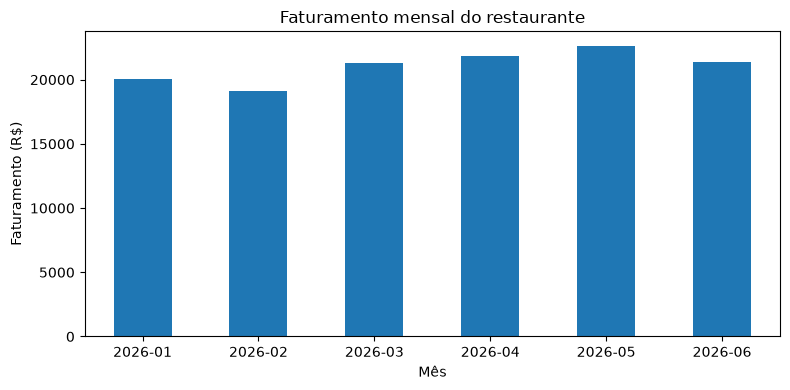

In [36]:
import matplotlib.pyplot as plt

faturamento_por_mes.plot(kind="bar", figsize=(8, 4))

plt.title("Faturamento mensal do restaurante")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
vendas.to_csv("../data/vendas_restaurante_tratadas.csv", index=False)

Vamos comparar o faturamento médio por dia em cada mês, considerando que os meses têm durações diferentes

In [38]:
faturamento_por_dia = vendas.groupby("data")["valor_total"].sum()

media_diaria_por_mes = faturamento_por_dia.groupby(
    faturamento_por_dia.index.to_period("M")
).mean()

media_diaria_por_mes.round(2)

data
2026-01    647.58
2026-02    683.64
2026-03    687.48
2026-04    727.80
2026-05    730.00
2026-06    711.67
Freq: M, Name: valor_total, dtype: float64

Dias da semana com maior faturamento

In [39]:
media_por_dia_semana = faturamento_por_dia.groupby(
    faturamento_por_dia.index.dayofweek
).mean()

media_por_dia_semana.round(2)

data
0     565.04
1     586.27
2     573.16
3     567.42
4     556.31
5    1089.04
6     944.15
Name: valor_total, dtype: float64

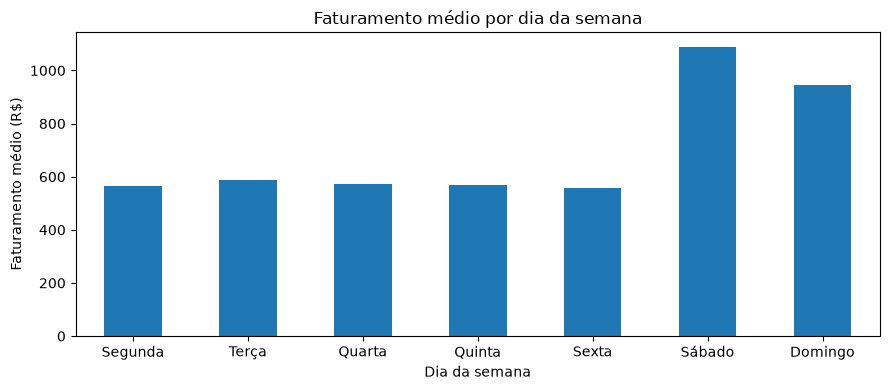

In [40]:
media_por_dia_semana.index = [
    "Segunda", "Terça", "Quarta", "Quinta",
    "Sexta", "Sábado", "Domingo"
]

media_por_dia_semana.plot(kind="bar", figsize=(9, 4))

plt.title("Faturamento médio por dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel("Faturamento médio (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Observações finais:

O faturamento total foi de R$ 126.343,00.
O Prato feito liderou em faturamento e quantidade vendida.
Maio teve o maior faturamento mensal e a maior média diária.
Fevereiro teve o menor total mensal, mas superou janeiro na média diária.
Sábado e domingo tiveram as maiores médias de faturamento diário. 

3 registros com quantidade zero foram separados para análise.

In [41]:
vendas_para_revisao.to_csv(
    "../data/vendas_restaurante_para_revisao.csv",
    index=False
)

In [42]:
vendas_para_revisao.shape

(3, 6)

In [43]:
print("Base tratada:", vendas.shape)
print("Registros para revisão:", vendas_para_revisao.shape)
print("Campos vazios:", vendas.isna().sum().sum())
print("Faturamento:", vendas["valor_total"].sum())

Base tratada: (4309, 7)
Registros para revisão: (3, 6)
Campos vazios: 0
Faturamento: 126343.0


In [44]:
vendas[vendas.isna().any(axis=1)]

,data,produto,categoria,quantidade,preco_unitario,forma_pagamento,valor_total
